In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import confusion_matrix

from sklearn.metrics import roc_curve
from sklearn.metrics import RocCurveDisplay

from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

In [2]:
# Parameters for the synthetic data
scale = 5
size = 500
# Generate class 1 out of a normal distribution
class1_x = np.random.normal(loc=10, scale=scale, size=size)
class1_y = np.random.normal(loc=1, scale=scale, size=size)
# Generate class 2 out of a normal distribution
class2_x = np.random.normal(loc=1, scale=scale, size=size)
class2_y = np.random.normal(loc=5, scale=scale, size=size)

<Axes: >

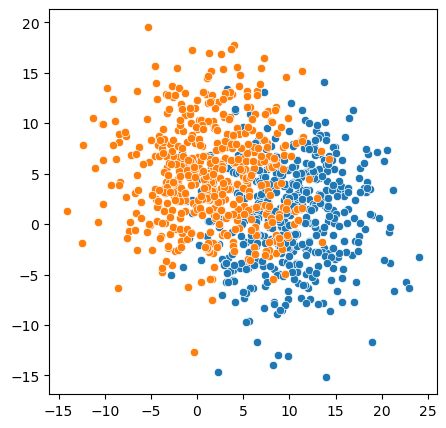

In [3]:
# Plot both to show how much they intersect
plt.figure(figsize=(5, 5))
sns.scatterplot(x=class1_x, y=class1_y)
sns.scatterplot(x=class2_x, y=class2_y)

In [4]:
df_class1 = pd.DataFrame()
df_class1['x'] = class1_x
df_class1['y'] = class1_y
df_class1['class'] = 0

df_class2 = pd.DataFrame()
df_class2['x'] = class2_x
df_class2['y'] = class2_y
df_class2['class'] = 1

In [5]:
df = pd.concat([df_class1, df_class2], ignore_index=True)
df

,x,y,class
0,3.397135,5.553341,0
1,9.983704,-2.266275,0
2,3.887668,-4.511738,0
3,5.280688,0.782997,0
4,8.810409,-1.983553,0
...,...,...,...
995,5.394316,11.615444,1
996,-0.635387,-0.928447,1
997,3.477413,10.416942,1
998,-1.863204,4.720384,1


In [6]:
# Get the dependent and independent variables
X = df.drop(columns=['class'])
y = df['class']
# Split train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)
# Create the model object
model = GaussianNB()
# Fit the model to the training data
model.fit(X_train, y_train)

GaussianNB()

In [7]:
# Predict the classes on the test data
y_pred = model.predict(X_test)
# Show the first 10 entries
y_pred[:10]

array([0, 1, 0, 0, 1, 0, 0, 1, 1, 0], dtype=int64)

In [8]:
# Predict the classes on the test data, 
# and return the probabilities for each class
y_proba = model.predict_proba(X_test)
# Show the first 10 entries
y_proba[:10]

array([[0.55627046, 0.44372954],
       [0.18020782, 0.81979218],
       [0.84456333, 0.15543667],
       [0.91209259, 0.08790741],
       [0.04200807, 0.95799193],
       [0.86190803, 0.13809197],
       [0.98776579, 0.01223421],
       [0.25043837, 0.74956163],
       [0.03141296, 0.96858704],
       [0.99575879, 0.00424121]])

<Axes: xlabel='x', ylabel='y'>

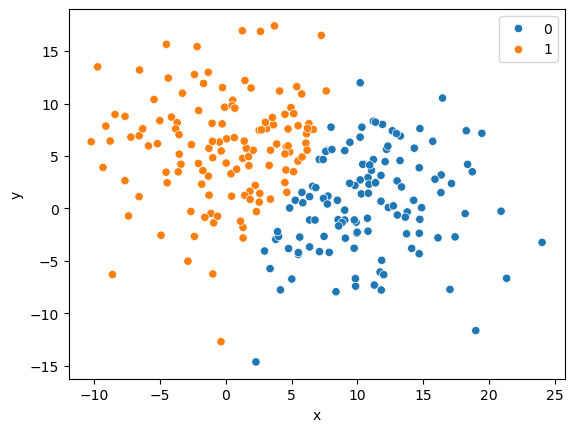

In [9]:
# Show the predictions
sns.scatterplot(x=X_test['x'], y=X_test['y'], hue=y_pred)

In [10]:
def calculate_tpr_fpr(y_real, y_pred):
    '''
    Calculates the True Positive Rate (tpr) and the True Negative Rate (fpr) based on real and predicted observations

    Args:
        y_real: The list or series with the real classes
        y_pred: The list or series with the predicted classes

    Returns:
        tpr: The True Positive Rate of the classifier
        fpr: The False Positive Rate of the classifier
    '''

    # Calculates the confusion matrix and recover each element
    cm = confusion_matrix(y_real, y_pred)
    TN = cm[0, 0]
    FP = cm[0, 1]
    FN = cm[1, 0]
    TP = cm[1, 1]

    # Calculates tpr and fpr
    tpr = TP / (TP + FN)  # sensitivity - true positive rate
    fpr = 1 - TN / (TN + FP)  # 1-specificity - false positive rate

    return tpr, fpr

In [11]:
def get_n_roc_coordinates(y_real, y_proba, resolution=50):
    '''
    Calculates "n" ROC Curve coordinates (tpr and fpr) by manipulating the threshold used to predict the class.

    Args:
        y_real: The list or series with the real classes.
        y_proba: The array with the probabilities for each class, obtained by using the `.predict_proba()` method.
        resolution: Defines how many divisions the threshold will have, and how many coordinates will be calculated (default = 50).

    Returns:
        tpr_list: The list of TPRs representing each threshold.
        fpr_list: The list of FPRs representing each threshold.
    '''
    tpr_list = [0]
    fpr_list = [0]
    for i in range(resolution):
        threshold = i/resolution
        y_pred = y_proba[:, 1] > threshold
        tpr, fpr = calculate_tpr_fpr(y_real, y_pred)
        tpr_list.append(tpr)
        fpr_list.append(fpr)
    return tpr_list, fpr_list

In [12]:
def plot_roc_curve(tpr, fpr, scatter=True):
    '''
    Plots the ROC Curve by using the list of coordinates (tpr and fpr).

    Args:
        tpr: The list of TPRs representing each coordinate.
        fpr: The list of FPRs representing each coordinate.
        scatter: When True, the points used on the calculation will be plotted with the line (default = True).
    '''
    plt.figure(figsize=(5, 5))
    if scatter:
        sns.scatterplot(x=fpr, y=tpr)
    sns.lineplot(x=fpr, y=tpr)
    sns.lineplot(x=[0, 1], y=[0, 1], color='green')
    plt.xlim(-0.05, 1.05)
    plt.ylim(-0.05, 1.05)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

In [13]:
# Calculates 10 coordinates of the ROC Curve
tpr, fpr = get_n_roc_coordinates(y_test, y_proba, resolution=10)

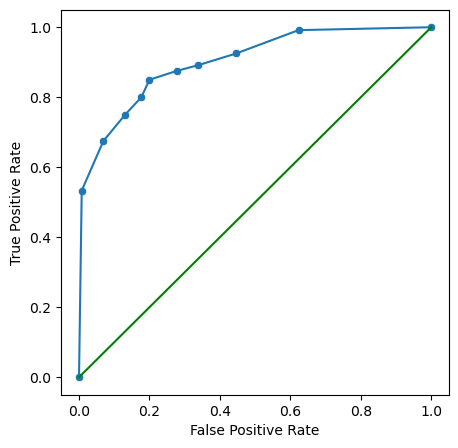

In [14]:
# Plots the ROC curve
plot_roc_curve(tpr, fpr)

In [15]:
def get_all_roc_coordinates(y_real, y_proba):
    '''
    Calculates all the ROC Curve coordinates (tpr and fpr) by considering each point as a treshold for the predicion of the class.

    Args:
        y_real: The list or series with the real classes.
        y_proba: The array with the probabilities for each class, obtained by using the `.predict_proba()` method.

    Returns:
        tpr_list: The list of TPRs representing each threshold.
        fpr_list: The list of FPRs representing each threshold.
    '''
    tpr_list = [0]
    fpr_list = [0]
    for i in range(len(y_proba)):
        threshold = y_proba[i, 1]
        y_pred = y_proba[:, 1] >= threshold
        tpr, fpr = calculate_tpr_fpr(y_real, y_pred)
        tpr_list.append(tpr)
        fpr_list.append(fpr)
    return tpr_list, fpr_list

In [16]:
# Calculates ALL coordinates of the ROC Curve
tpr, fpr = get_all_roc_coordinates(y_test, y_proba)

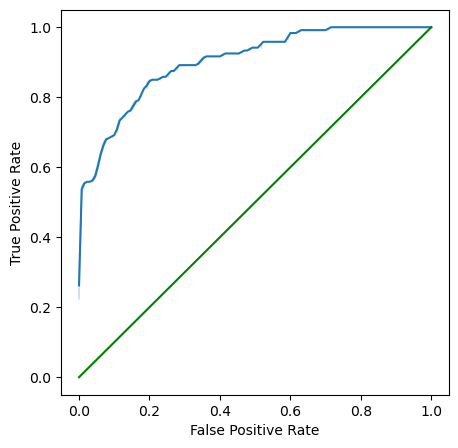

In [17]:
# Plots the ROC curve
plot_roc_curve(tpr, fpr, scatter=False)

In [18]:
def plot_sklearn_roc_curve(y_real, y_pred):
    '''
    Plots the ROC Curve with the sklearn methods by using the real observations and their predictions.

    Args:
        y_real: The list or series with the real classes
        y_pred: The list or series with the predicted classes
    '''
    fpr, tpr, _ = roc_curve(y_real, y_pred)
    roc_display = RocCurveDisplay(fpr=fpr, tpr=tpr).plot(label="Model ROC")
    plt.plot([0, 1], [0, 1], color = 'g')
    roc_display.figure_.set_size_inches(5, 5)

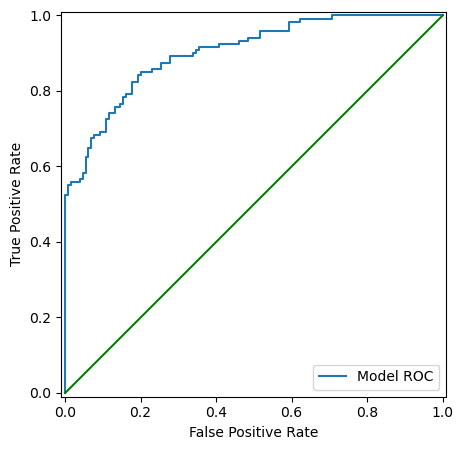

In [19]:
# Plots the ROC curve using the sklearn methods
plot_sklearn_roc_curve(y_test, y_proba[:, 1])

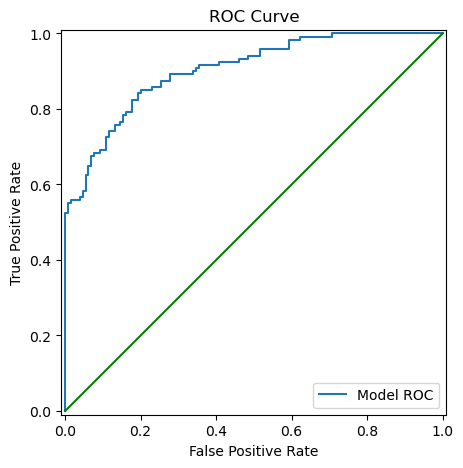

In [ ]:
y_proba = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_display = RocCurveDisplay(fpr=fpr, tpr=tpr).plot(label='Model ROC')

plt.plot([0, 1], [0, 1], color='g')
roc_display.figure_.set_size_inches(5, 5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

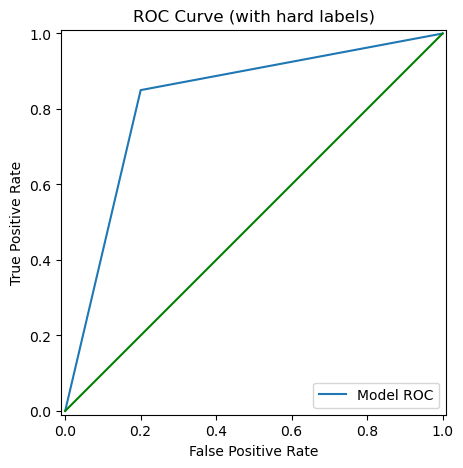

In [23]:
y_pred = model.predict(X_test)
fpr, tpr, _ = roc_curve(y_test, y_pred)
roc_display = RocCurveDisplay(fpr=fpr, tpr=tpr).plot(label='Model ROC')

plt.plot([0, 1], [0, 1], color='g')
roc_display.figure_.set_size_inches(5, 5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (with hard labels)")
plt.show()

In [21]:
def evaluate_classifier(y_real, y_pred):
    '''
    Prints the accuracy, precision, recall and roc auc scores for the classifier.

    Args:
        y_real: The list or series with the real classes
        y_pred: The list or series with the predicted classes
    '''
    print(f"Accuracy: {accuracy_score(y_real, y_pred):.4f}")
    print(f"Precision: {precision_score(y_real, y_pred):.4f}")
    print(f"Recall: {recall_score(y_real, y_pred):.4f}")
    print(f"ROC AUC: {roc_auc_score(y_real, y_pred):.4f}")

In [22]:
evaluate_classifier(y_test, y_pred)

Accuracy: 0.8240
Precision: 0.7969
Recall: 0.8500
ROC AUC: 0.8250
